# 1. Data analysis
The SBA loan data: how it was cleaned, and what it shows. The cleaning code is in `src/prep.py`.

In [1]:
# ---- setup: libraries, our own code (src/), and a helper to save charts
import sys
sys.path.insert(0, "..")            # lets the notebook find the src/ folder
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from src import prep, train, stats

CHARTS_FOLDER = prep.PROJECT_FOLDER / "outputs" / "figures"

def save_chart(name):
    """Save the current chart as a PNG in outputs/figures and show it."""
    plt.savefig(CHARTS_FOLDER / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()

def light_style():
    """White background (used for charts 01-14)."""
    mpl.rcdefaults()
    sns.set_theme(style="whitegrid")

def dark_style():
    """Dark background matching the app (used for charts 15-25)."""
    mpl.rcParams.update({"figure.facecolor": "#0e1117", "axes.facecolor": "#0e1117",
                         "savefig.facecolor": "#0e1117", "text.color": "#e8eaed",
                         "axes.labelcolor": "#e8eaed", "axes.titlecolor": "#e8eaed",
                         "xtick.color": "#e8eaed", "ytick.color": "#e8eaed",
                         "axes.edgecolor": "#3a4050", "grid.color": "#3a4050",
                         "legend.labelcolor": "#e8eaed"})

## Cleaning and leakage
`prep.clean()` removes loans with no result, turns money text into numbers, fixes category codes
and adds five new columns. It also removes columns that are only filled in **after** a loan fails.
Here is the proof for one of them, `ChgOffDate`:

In [2]:
raw = pd.read_csv(prep.RAW_FILE, dtype=str, usecols=["MIS_Status", "ChgOffDate"])
print("raw file:", len(raw), "loans")

# for each result (paid / charged off): what share of loans have a charge-off date?
raw["has_date"] = raw["ChgOffDate"].notna()
share_with_date = raw.groupby("MIS_Status")["has_date"].mean() * 100
print(share_with_date.round(2))

loans = prep.load_clean()
print("clean data:", len(loans), "loans | default rate", round(loans["default"].mean() * 100, 2), "%")

raw file: 899164 loans
MIS_Status
CHGOFF    99.97
P I F      0.67
Name: has_date, dtype: float64


clean data: 897167 loans | default rate 17.56 %


## 1. Class balance — about 82 / 18

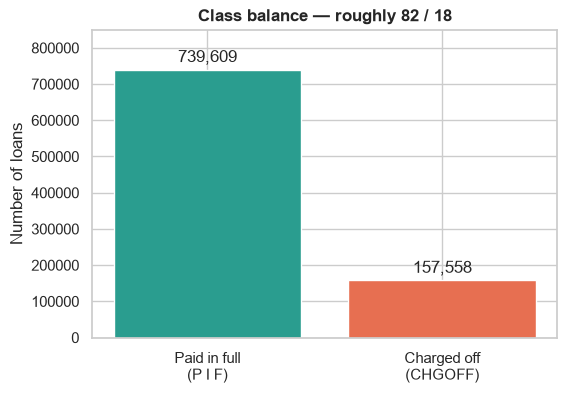

In [3]:
light_style()
paid = (loans["default"] == 0).sum()
not_paid = (loans["default"] == 1).sum()

figure, axis = plt.subplots(figsize=(6, 4))
bars = axis.bar(["Paid in full\n(P I F)", "Charged off\n(CHGOFF)"], [paid, not_paid],
                color=["#2a9d8f", "#e76f51"])
axis.bar_label(bars, fmt="{:,.0f}", padding=3)
axis.margins(y=0.15)
axis.set_ylabel("Number of loans")
axis.set_title("Class balance — roughly 82 / 18", fontweight="bold")
save_chart("01_class_balance")

## 2. Default rate by industry

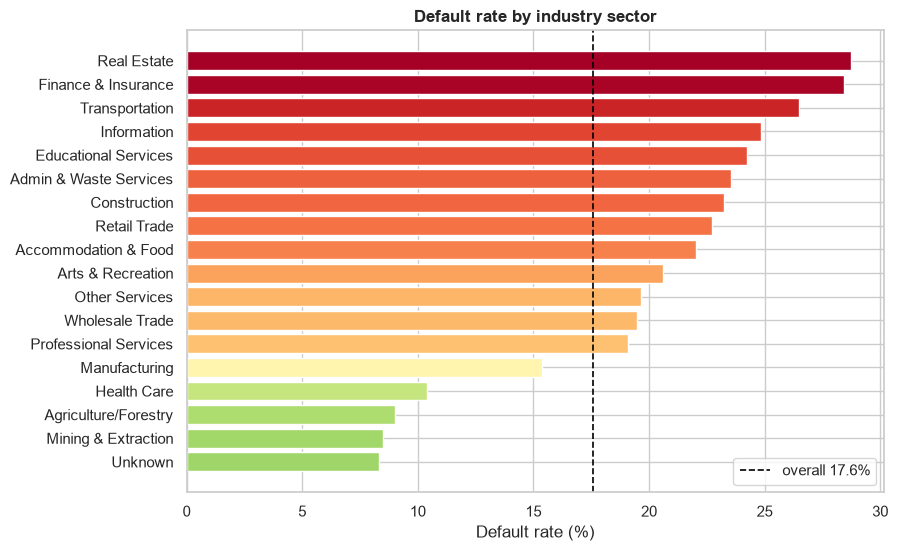

In [4]:
overall = loans["default"].mean() * 100

# default rate of each industry with at least 1,000 loans, worst first
by_industry = loans.groupby("NAICS_sector")["default"].agg(["mean", "count"])
by_industry = by_industry[by_industry["count"] >= 1000].sort_values("mean", ascending=False)

figure, axis = plt.subplots(figsize=(9, 6))
colours = plt.cm.RdYlGn_r(by_industry["mean"] / by_industry["mean"].max())
axis.barh(by_industry.index, by_industry["mean"] * 100, color=colours)
axis.invert_yaxis()
axis.axvline(overall, color="black", ls="--", lw=1.2, label="overall " + str(round(overall, 1)) + "%")
axis.set_xlabel("Default rate (%)")
axis.set_title("Default rate by industry sector", fontweight="bold")
axis.legend()
save_chart("02_default_by_sector")

## 3. Default rate by state — the 10 worst and the 10 best

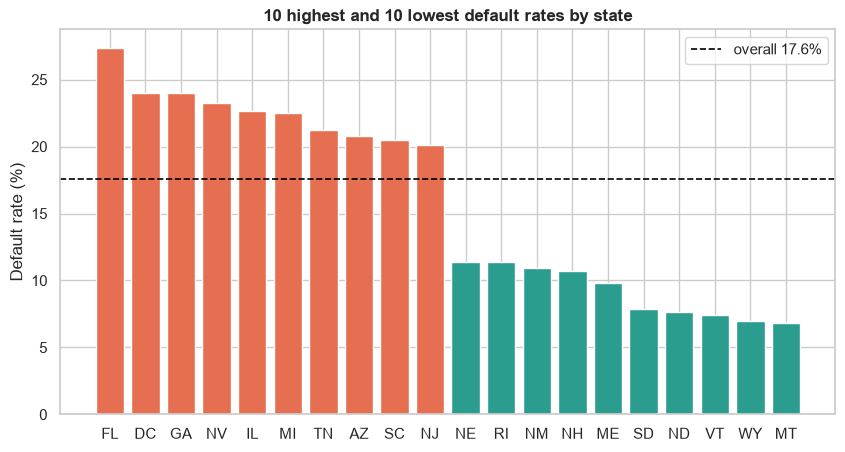

In [5]:
by_state = loans.groupby("State")["default"].agg(["mean", "count"])
by_state = by_state[by_state["count"] >= 1000].sort_values("mean", ascending=False)
worst_and_best = pd.concat([by_state.head(10), by_state.tail(10)])

figure, axis = plt.subplots(figsize=(10, 5))
axis.bar(worst_and_best.index, worst_and_best["mean"] * 100, color=["#e76f51"] * 10 + ["#2a9d8f"] * 10)
axis.axhline(overall, color="black", ls="--", lw=1.2, label="overall " + str(round(overall, 1)) + "%")
axis.set_ylabel("Default rate (%)")
axis.set_title("10 highest and 10 lowest default rates by state", fontweight="bold")
axis.legend()
save_chart("03_default_by_state")

## 4. Correlation — which numbers move together
`Term` is left out: its recorded value depends on the outcome (notebook 3).

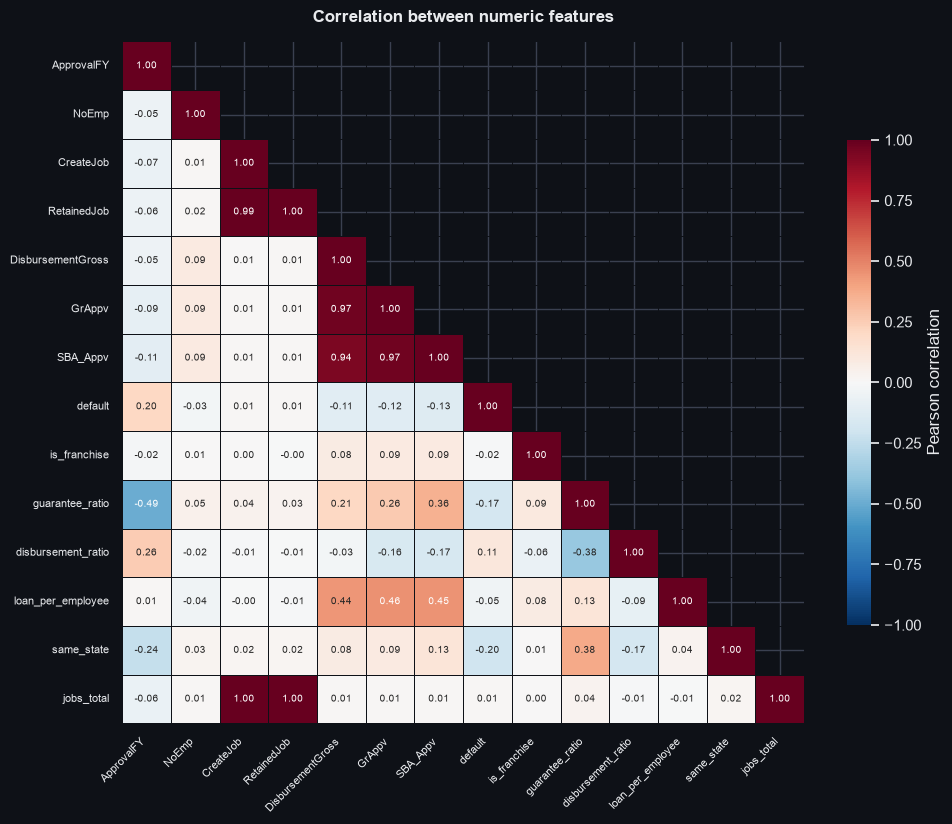

ApprovalFY            0.205
same_state           -0.196
guarantee_ratio      -0.175
SBA_Appv             -0.132
GrAppv               -0.120
disbursement_ratio    0.113
Name: default, dtype: float64


In [6]:
dark_style()
numbers = loans.select_dtypes("number").drop(columns=["Term"])
correlation = numbers.corr()
hide_top_half = np.triu(np.ones_like(correlation, dtype=bool), k=1)

figure, axis = plt.subplots(figsize=(11, 9))
sns.heatmap(correlation, mask=hide_top_half, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.4, linecolor="#0e1117",
            square=True, cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=axis)
axis.set_title("Correlation between numeric features", fontweight="bold", pad=14)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
save_chart("15_correlation_matrix")

# the strongest links with "default" (positive or negative)
links = correlation["default"].drop("default")
strongest = links.abs().sort_values(ascending=False).index
print(links[strongest].round(3).head(6))

## 5. Distributions — repaid vs defaulted
Money and headcount use a log scale because they range from very small to very large.

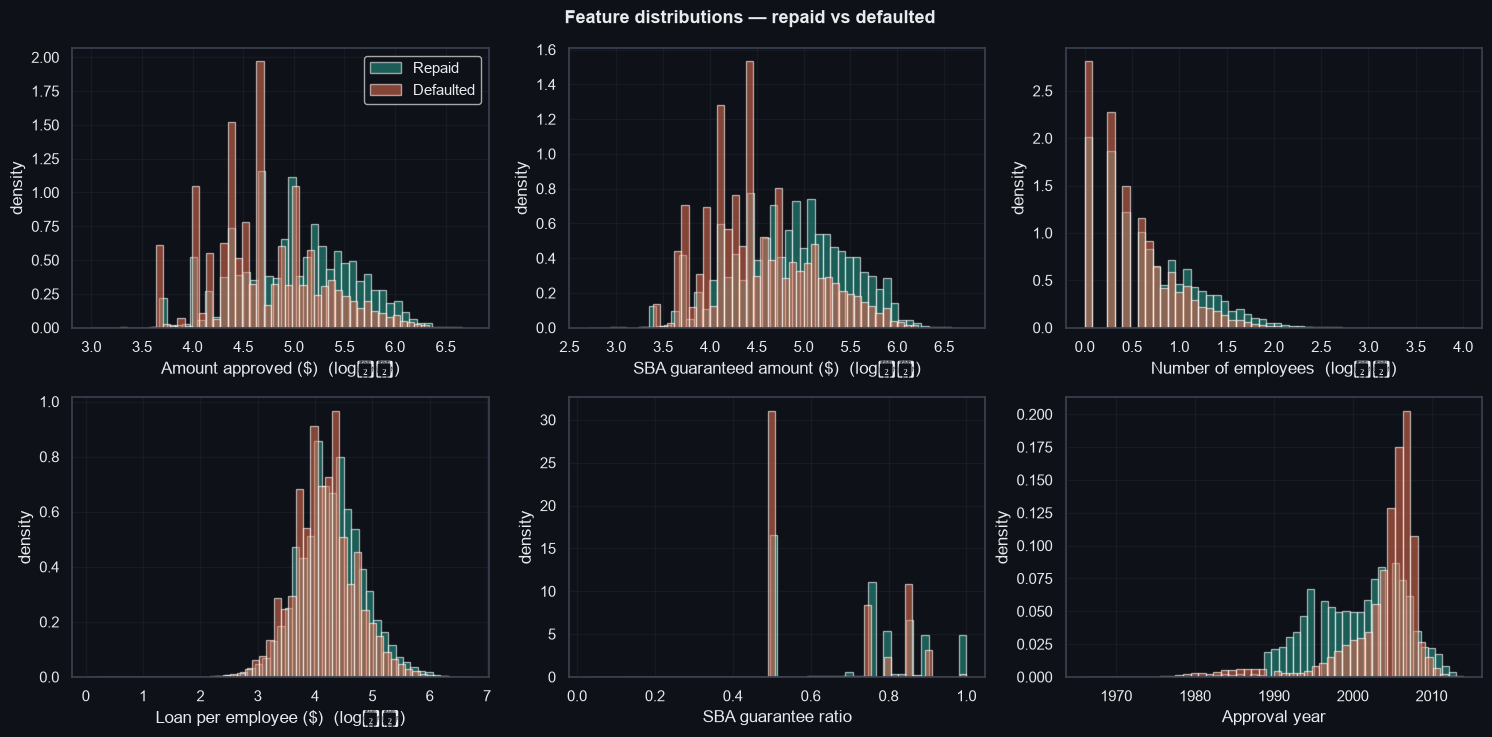

In [7]:
charts = [("GrAppv", "Amount approved ($)", True),
          ("SBA_Appv", "SBA guaranteed amount ($)", True),
          ("NoEmp", "Number of employees", True),
          ("loan_per_employee", "Loan per employee ($)", True),
          ("guarantee_ratio", "SBA guarantee ratio", False),
          ("ApprovalFY", "Approval year", False)]

figure, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for axis, (column, label, use_log) in zip(axes.ravel(), charts):
    data = loans[[column, "default"]].dropna()
    if use_log:
        data = data[data[column] > 0].copy()
        data[column] = np.log10(data[column])
        label = label + "  (log₁₀)"
    repaid = data[data["default"] == 0][column]
    defaulted = data[data["default"] == 1][column]
    axis.hist(repaid, bins=50, density=True, alpha=0.55, color="#2a9d8f", label="Repaid")
    axis.hist(defaulted, bins=50, density=True, alpha=0.55, color="#e76f51", label="Defaulted")
    axis.set_xlabel(label)
    axis.set_ylabel("density")
    axis.grid(alpha=0.2)
axes[0, 0].legend()
figure.suptitle("Feature distributions — repaid vs defaulted", fontweight="bold", fontsize=13)
plt.tight_layout()
save_chart("16_distributions")

## 6. Outliers — the 1.5 × IQR rule
A value is an outlier if it is far below the 25th percentile or far above the 75th.
They are **kept**: they are real loans, and tree models are not thrown off by large numbers.

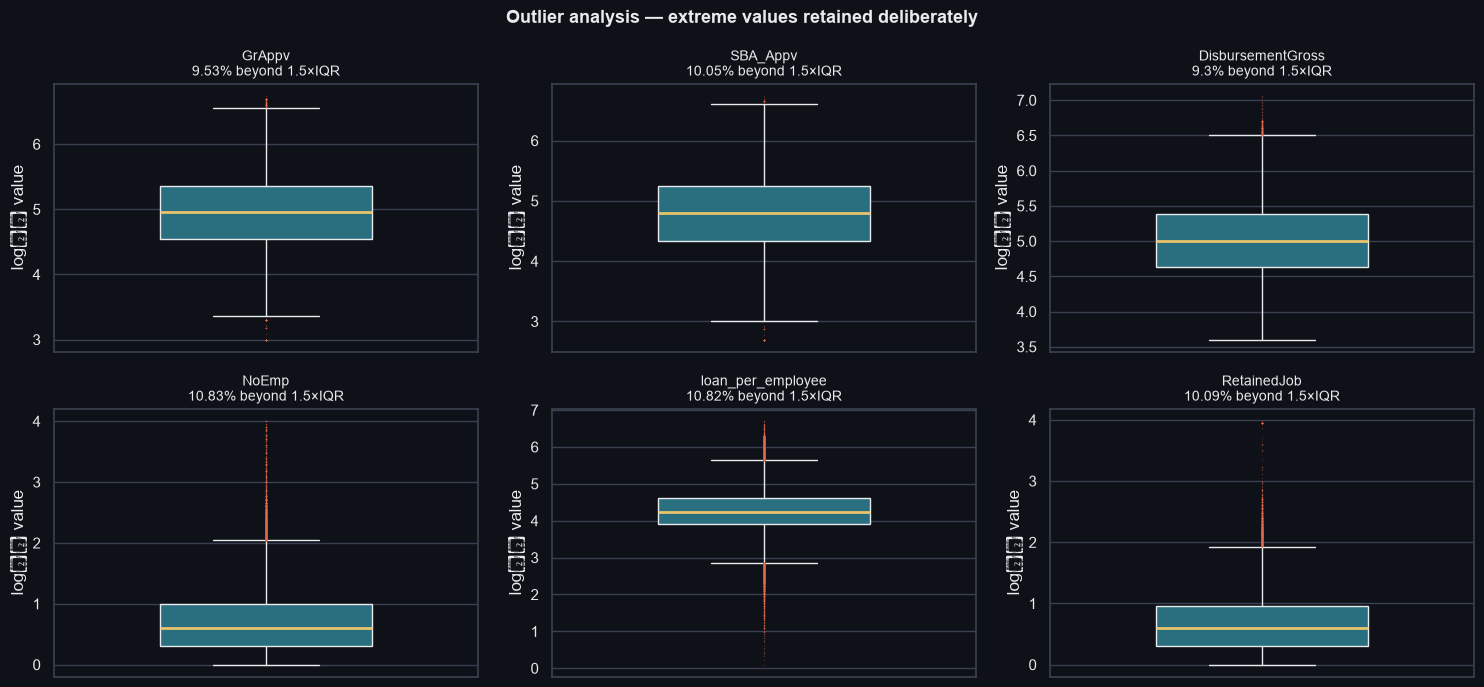

In [8]:
columns = ["GrAppv", "SBA_Appv", "DisbursementGross", "NoEmp", "loan_per_employee", "RetainedJob"]

figure, axes = plt.subplots(2, 3, figsize=(15, 7))
for axis, column in zip(axes.ravel(), columns):
    values = loans[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    is_outlier = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    outlier_percent = is_outlier.mean() * 100

    axis.boxplot(np.log10(values[values > 0]), widths=0.5, patch_artist=True,
                 boxprops=dict(facecolor="#2a6f7f", color="#e8eaed"),
                 medianprops=dict(color="#e9c46a", lw=2),
                 whiskerprops=dict(color="#e8eaed"), capprops=dict(color="#e8eaed"),
                 flierprops=dict(marker=".", markersize=2, markerfacecolor="#e76f51",
                                 markeredgecolor="none", alpha=0.3))
    axis.set_title(column + "\n" + str(round(outlier_percent, 2)) + "% beyond 1.5×IQR", fontsize=10)
    axis.set_ylabel("log₁₀ value")
    axis.set_xticks([])
figure.suptitle("Outlier analysis — extreme values retained deliberately", fontweight="bold", fontsize=13)
plt.tight_layout()
save_chart("17_outliers")

## 7. Industry × state heatmap
Each number = loans not paid back out of 100. Squares with fewer than 100 loans are left blank.

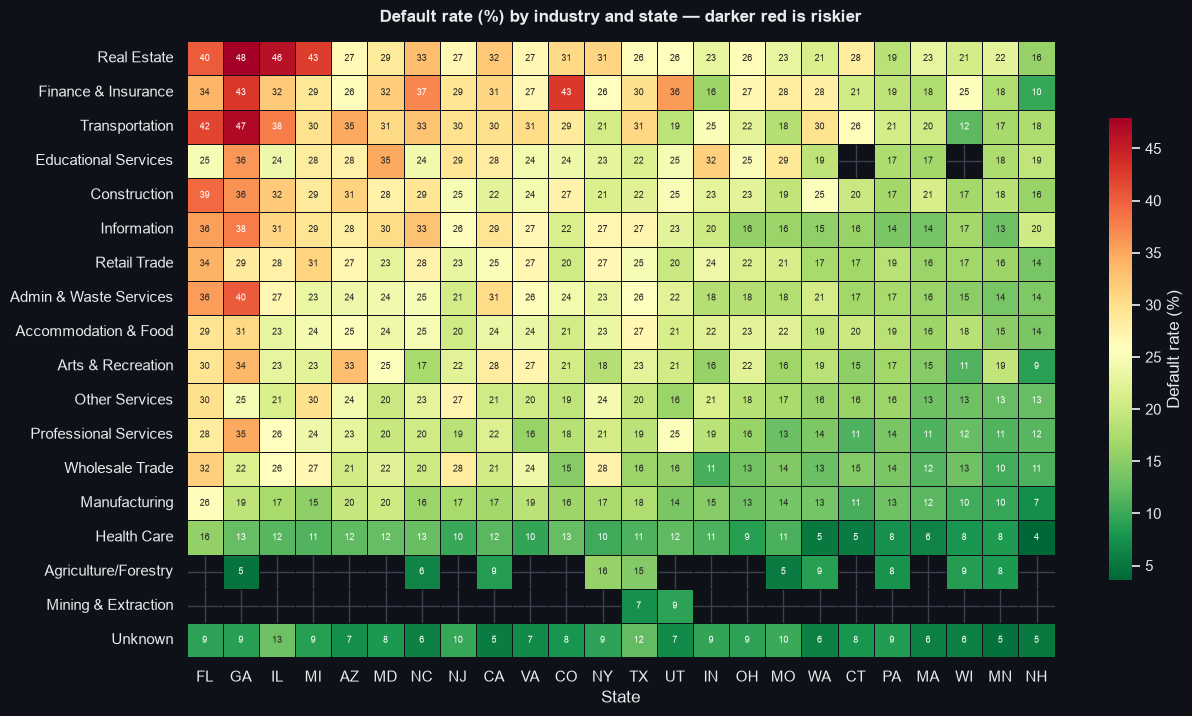

In [9]:
# the 24 states with the most loans
top_states = loans["State"].value_counts().head(24).index
some_loans = loans[loans["State"].isin(top_states)]

rate = some_loans.pivot_table(index="NAICS_sector", columns="State", values="default", aggfunc="mean") * 100
count = some_loans.pivot_table(index="NAICS_sector", columns="State", values="default", aggfunc="size")
rate = rate.where(count >= 100)                        # blank if fewer than 100 loans
rate = rate.dropna(how="all").dropna(how="all", axis=1)

# order rows and columns from riskiest to safest
rate = rate.loc[rate.mean(axis=1).sort_values(ascending=False).index]
rate = rate[rate.mean().sort_values(ascending=False).index]

figure, axis = plt.subplots(figsize=(14, 8))
sns.heatmap(rate, cmap="RdYlGn_r", annot=True, fmt=".0f", annot_kws={"size": 6.5}, linewidths=0.4,
            linecolor="#0e1117", cbar_kws={"label": "Default rate (%)", "shrink": 0.75}, ax=axis)
axis.set_title("Default rate (%) by industry and state — darker red is riskier", fontweight="bold", pad=14)
axis.set_xlabel("State")
axis.set_ylabel("")
save_chart("18_regional_heatmap")